# Reaction-network Koopman: species graphs, log concentrations, and kinetic timescales

A mass-action reaction network is a graph dynamical system with a known
answer key. Species are nodes, the stoichiometry says which species
drive which, and the Jacobian at equilibrium gives the true relaxation
timescales. This notebook trains graph Koopman models on the
Michaelis-Menten card `reaction_michaelis_menten_v1` and checks them
against that structure: forecast error at several horizons, the learned
spectrum after ResDMD gating, implied timescales against the oracle,
and atom balance against the bias of the log floor.

It compares five neural encodings of the same data (a species graph
with a graph-coupled operator, the same with a per-node operator, a
reaction hypergraph, a species-reaction bipartite graph, and a
raw-concentration model with a conserving projection) against three
model-free controls (`hold_last`, flat DMD, polynomial EDMD). It ends
with one rate-constant shift.

**Honesty.** This is a diagnostic / teaching notebook on a four-species
system, not a production kinetics benchmark. Every neural model is a
short CPU fit (`EPOCHS` below), so its numbers describe this budget and
not a tuned model. Some results are negative, and the notebook reports
them as such. The oracle spectrum is the **linearization** at one
equilibrium and describes the late-time approach only. The notebook
does **not** download METR-LA or any other data and does not need the
`[cantera]` extra.

## Setup

Imports, seeds, and the training budget. The notebook runs on CPU in a
few minutes. One PyTorch thread is faster than the default pool on
graphs this small. The helpers below are used by every section:

- `SpeciesIdentityEncoder` appends a one-hot species index to each
  node's features (see *Motivation*).
- `with_features` swaps the node features of a card sequence while
  keeping its graph.
- `forecast_mae` rolls a forecaster out from every test origin and
  returns the mean absolute error at each horizon.
- `PooledLeastSquares` is flat DMD (degree 1) or polynomial EDMD
  (degree 2) fitted on consecutive pairs pooled over all training
  trajectories. `DMDBaseline` and `EDMDBaseline` fit one sequence, and
  concatenating trajectories would add pairs across their boundaries.

In [1]:
from __future__ import annotations

import math
import os
import time
import warnings

from tqdm.std import TqdmWarning

warnings.filterwarnings("ignore", category=TqdmWarning)

import matplotlib

if os.environ.get("PYTEST_CURRENT_TEST"):
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import torch

import koopman_graph
from koopman_graph import (
    GraphKoopmanModel,
    GraphSnapshotSequence,
    HypergraphDecoder,
    HypergraphEncoder,
    MultiTrajectory,
    RelGraphDecoder,
    RelGraphEncoder,
)
from koopman_graph.analysis import implied_timescales, resdmd
from koopman_graph.data import HeteroGraphSnapshotSequence
from koopman_graph.datasets import ReactionNetworkBenchmark
from koopman_graph.datasets.reaction import (
    PRODUCT_RELATION,
    REACTANT_RELATION,
    REACTION_NODE,
    SPECIES_NODE,
    element_balance_violation,
    integrate_reaction_system,
    michaelis_menten,
    species_reaction_bipartite,
)
from koopman_graph.nn import LinearConservingDecoder, SAGEDecoder, SAGEEncoder
from koopman_graph.training import LossWeights

SEED = 0
_ = torch.manual_seed(SEED)
torch.set_num_threads(1)
EPOCHS = 30  # CPU budget of every neural arm; the Results text describes this run
HORIZONS = (1, 5, 20)
HIDDEN, LATENT = 32, 8
FIT = {"epochs": EPOCHS, "lr": 1e-2, "rollout_horizon": 16, "max_grad_norm": 1.0}
LOSS = LossWeights(
    reconstruction=1.0, forward=1.0, backward=0.5, rollout=0.5, eigenvalue=0.01
)
CLOCK = time.perf_counter()

print("koopman_graph", koopman_graph.__version__)


class SpeciesIdentityEncoder(torch.nn.Module):
    """Wrap an encoder so species i sees its features plus onehot(i)."""

    def __init__(self, encoder: torch.nn.Module, num_species: int) -> None:
        super().__init__()
        self.encoder = encoder
        self.latent_dim = encoder.latent_dim
        self.hidden_channels = encoder.hidden_channels
        self.register_buffer("identity", torch.eye(num_species))

    def forward(self, x, edge_index=None, edge_weight=None):
        if hasattr(x, "x"):  # a snapshot
            x, edge_index, edge_weight = x.x, x.edge_index, x.edge_weight
        repeats = x.shape[0] // self.identity.shape[0]  # k stacked snapshots
        onehot = self.identity.to(x).repeat(repeats, 1)
        return self.encoder(torch.cat([x, onehot], dim=1), edge_index, edge_weight)


def with_features(sequence, values: torch.Tensor):
    """Copy a sequence and replace node features by values (T, S)."""
    snapshots = []
    for t, snapshot in enumerate(sequence):
        snapshot = snapshot.clone()
        if isinstance(sequence, HeteroGraphSnapshotSequence):
            snapshot[SPECIES_NODE].x = values[t].unsqueeze(-1).float()
        else:
            snapshot.x = values[t].unsqueeze(-1).float()
        snapshots.append(snapshot)
    if isinstance(sequence, HeteroGraphSnapshotSequence):
        return HeteroGraphSnapshotSequence(snapshots)
    return GraphSnapshotSequence(snapshots, timestamps=sequence.timestamps)


def species_values(snapshot) -> torch.Tensor:
    """Channel 0 of the species nodes, shape (S,)."""
    if hasattr(snapshot, "node_types"):
        return snapshot[SPECIES_NODE].x[:, 0]
    return snapshot.x[:, 0]


def forecast_mae(forecaster, sequences, scale, horizons=HORIZONS) -> dict[int, float]:
    """Mean |error| at each horizon over every origin, rescaled by scale (S,)."""
    errors = {h: [] for h in horizons}
    with torch.no_grad():
        for sequence in sequences:
            for origin in range(len(sequence) - max(horizons)):
                predicted = forecaster.predict(sequence[origin], max(horizons))
                for h in horizons:
                    diff = species_values(predicted[h - 1]) - species_values(
                        sequence[origin + h]
                    )
                    errors[h].append((diff.double() * scale).abs().mean())
    return {h: float(torch.stack(v).mean()) for h, v in errors.items()}


class HoldLast:
    """Persistence control: every future state equals the current one."""

    def predict(self, initial, steps):
        return [initial] * steps


class PooledLeastSquares:
    """Flat DMD (degree=1) or polynomial EDMD (degree=2) on pooled pairs."""

    def __init__(self, sequences, degree: int) -> None:
        self.degree = degree
        states = [
            torch.stack([species_values(s) for s in seq]).double() for seq in sequences
        ]
        left = torch.cat([self.lift(x[:-1]) for x in states])
        right = torch.cat([self.lift(x[1:]) for x in states])
        self.K = torch.linalg.lstsq(left, right).solution

    def lift(self, x: torch.Tensor) -> torch.Tensor:
        if self.degree == 1:
            return x
        rows, cols = torch.triu_indices(x.shape[-1], x.shape[-1])
        ones = torch.ones(*x.shape[:-1], 1, dtype=x.dtype)
        return torch.cat([x, ones, x[..., rows] * x[..., cols]], dim=-1)

    def predict(self, initial, steps):
        psi = self.lift(species_values(initial).double().unsqueeze(0))
        out = []
        for _ in range(steps):
            psi = psi @ self.K  # advance in the lifted space
            snapshot = initial.clone()
            snapshot.x = (
                psi[0, : initial.num_nodes].float().unsqueeze(-1)
            )  # linear terms
            out.append(snapshot)
        return out

koopman_graph 0.16.0


## Motivation and background

For a closed network with species concentrations $c \in \mathbb{R}^S$
and stoichiometric matrix $N$, mass-action kinetics is
$\dot c = N\,r(c)$. Two pieces of that structure suit a graph Koopman
model:

- **Species as nodes, stoichiometry as coupling.** The card's
  `species_influence` graph has an edge $s \to t$ when $s$ is a reactant
  of a reaction that changes $t$. A graph-coupled operator
  (`koopman="graph"`) can only mix latent states along those edges.
- **Log concentrations.** Concentrations span decades and must stay
  positive. The card's features are $\log \max(c, \varepsilon)$ with a
  floor $\varepsilon = 10^{-8}$. Decoding with $\exp$ keeps forecasts
  positive. The floor adds a bias of $\varepsilon$ per species, so
  balance errors below the floor bias are not model errors.

The **oracle** is the Jacobian $J = N\,\partial r/\partial c$ at the
equilibrium reached from the middle of the card's initial ranges. Its
non-zero eigenvalues $\lambda$ are relaxation rates with timescales
$-1/\mathrm{Re}\,\lambda$. A discrete operator with step $\Delta t$
should have the eigenvalue $e^{\lambda\Delta t}$. Each conservation
law (here the enzyme and substrate totals, rows of the element matrix
$E$ with $E N = 0$) adds an eigenvalue $1$.

**Shared modules can see a symmetry that the dynamics break.** The
SAGE encoder, the tied operator, and the decoder use the same weights
at every node. When two species have the same graph neighbourhood
(after normalization), the model must treat them identically.
`SpeciesIdentityEncoder` appends $\mathrm{onehot}(i)$ to the input of
species $i$, which acts as a learned per-species embedding through the
first layer. The decoder still reconstructs the log concentration only.

## Minimal example

Generate 24 trajectories of 48 steps (24 s, six times the slow oracle
timescale), split them by index
(70/10/20), and build species-graph sequences whose node feature is the
log concentration standardized per species with the training mean and
standard deviation. Errors are reported back in log-concentration units.

In [2]:
mm = ReactionNetworkBenchmark.generate(
    "reaction_michaelis_menten_v1", num_trajectories=24, num_timesteps=48
)
split = ReactionNetworkBenchmark.split(mm)
system, dt, transform = mm.system, mm.card["time_step"], mm.transform
S = system.num_species
log_train = transform.forward(split.train.concentrations)
mu = log_train.reshape(-1, S).mean(0)
sd = log_train.reshape(-1, S).std(0)


def standardized_sequences(dataset, graph_encoding="species_influence"):
    z = (transform.forward(dataset.concentrations) - mu) / sd
    return [
        with_features(dataset.sequence(i, graph_encoding=graph_encoding), z[i])
        for i in range(dataset.num_trajectories)
    ]


train_seqs = standardized_sequences(split.train)
test_seqs = standardized_sequences(split.test)
graph = train_seqs[0][0]
print("species", system.species, "elements", system.elements, "dt", dt)
print(
    "trajectories train/val/test",
    [p.num_trajectories for p in (split.train, split.val, split.test)],
)
print("influence edges", graph.edge_index.shape[1])


def species_graph_model(koopman="graph", in_channels=1):
    encoder = SpeciesIdentityEncoder(SAGEEncoder(in_channels + S, HIDDEN, LATENT), S)
    options = {"koopman": "graph", "koopman_adjacency": "dual_random_walk"}
    if koopman == "pernode":
        options = {}  # default per-node operator
    return GraphKoopmanModel(
        encoder,
        SAGEDecoder(LATENT, HIDDEN, in_channels),
        latent_dim=LATENT,
        time_step=dt,
        **options,
    )


_ = torch.manual_seed(SEED)
arm_a = species_graph_model()
tic = time.perf_counter()
history = arm_a.fit(MultiTrajectory(train_seqs), loss_weights=LOSS, **FIT)
arm_a.eval()
print(
    f"Arm A: {EPOCHS} epochs in {time.perf_counter() - tic:.0f} s, final loss {history.loss[-1]:.3f}"
)

results = {}
results["Arm A (species graph)"] = forecast_mae(arm_a, test_seqs, sd)
results["hold_last"] = forecast_mae(HoldLast(), test_seqs, sd)
for name in ("Arm A (species graph)", "hold_last"):
    print(f"{name:24s}", {h: round(v, 3) for h, v in results[name].items()})
assert all(math.isfinite(v) for v in results["Arm A (species graph)"].values())

species ('E', 'S', 'ES', 'P') elements ('Enz', 'Sub') dt 0.5
trajectories train/val/test [17, 2, 5]
influence edges 7


Arm A: 30 epochs in 17 s, final loss 0.151


Arm A (species graph)    {1: 0.153, 5: 0.466, 20: 1.036}
hold_last                {1: 0.082, 5: 0.278, 20: 0.981}


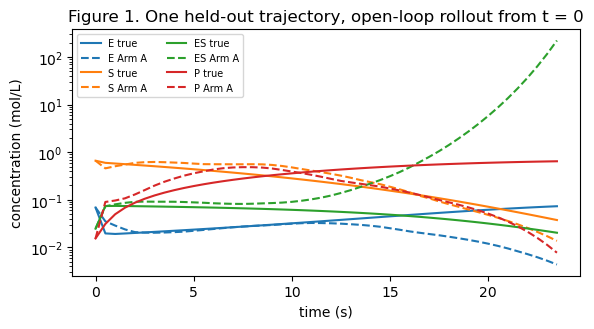

In [3]:
sequence = test_seqs[0]
with torch.no_grad():
    rollout = arm_a.predict(sequence[0], len(sequence) - 1)
truth_c = transform.inverse(
    torch.stack([species_values(s) for s in sequence]).double() * sd + mu
)
model_c = transform.inverse(
    torch.stack(
        [species_values(sequence[0])] + [species_values(s) for s in rollout]
    ).double()
    * sd
    + mu
)
times = mm.times
fig, ax = plt.subplots(figsize=(6.0, 3.4))
for k, name in enumerate(system.species):
    (line,) = ax.plot(times, truth_c[:, k], label=f"{name} true")
    ax.plot(times, model_c[:, k], "--", color=line.get_color(), label=f"{name} Arm A")
ax.set_yscale("log")
ax.set_xlabel("time (s)")
ax.set_ylabel("concentration (mol/L)")
ax.set_title("Figure 1. One held-out trajectory, open-loop rollout from t = 0")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Figure 1 shows the problem the next section diagnoses. The rollout
tracks the true trajectory for a few seconds, then drifts, and one
species grows without bound. A 30-epoch fit is far from converged, and
its forecast error is above `hold_last` (printed above).

## Progressive deep dive

**Spectrum, Nyquist flags, and ResDMD gating.** The graph operator of
Arm A has $S \times d$ eigenvalues. `implied_timescales` converts them
to timescales $-\Delta t / \ln|\lambda|$ and flags arguments near
$\pi$ (the Nyquist phase), where a mode oscillates faster than the
sampling resolves. The operator spectrum alone does not say which modes
the data support. ResDMD (Colbrook and Townsend) does: it treats the
frozen encodings $z_t$ of the test trajectories as a fixed dictionary,
fits EDMD on pooled pairs $(z_t, z_{t+1})$, and bounds each eigenpair's
residual. Pairs with residual above $0.1$ are discarded. The
dictionary is first whitened on its principal subspace, which leaves
eigenvalues and residuals unchanged but avoids rank-deficient Gram
matrices from saturated encodings.

In [4]:
operator = arm_a.spectrum(
    edge_index=graph.edge_index, num_nodes=S, edge_weight=graph.edge_weight
)
operator_eigs = operator.eigenvalues.detach().to(torch.complex128)
flags = implied_timescales(operator_eigs, lag_steps=1, timestep=dt, timestep_unit="s")
print(
    "operator eigenvalues",
    operator_eigs.numel(),
    "max |lambda|",
    round(float(operator_eigs.abs().max()), 4),
)
print("near-Nyquist modes", int(flags.aliasing_warning.sum()))


def frozen_encodings(model, sequences) -> torch.Tensor:
    with torch.no_grad():
        return torch.stack(
            [
                torch.stack([model.encode(s).reshape(-1) for s in seq])
                for seq in sequences
            ]
        ).double()


z = frozen_encodings(arm_a, test_seqs)
psi0 = z[:, :-1].reshape(-1, z.shape[-1])
psi1 = z[:, 1:].reshape(-1, z.shape[-1])
_, singular, vh = torch.linalg.svd(psi0, full_matrices=False)
rank = int((singular > 1e-8 * singular[0]).sum())
basis = vh[:rank].T / singular[:rank]
report = resdmd(psi0 @ basis, psi1 @ basis, tolerance=0.1)
gate = report.residuals < 0.1
print(
    f"ResDMD: dictionary {z.shape[-1]} -> rank {rank}, kept {int(gate.sum())} of {gate.numel()} eigenpairs"
)

operator eigenvalues 32 max |lambda| 1.0765
near-Nyquist modes 0
ResDMD: dictionary 32 -> rank 32, kept 13 of 32 eigenpairs


**Encoder or operator?** A short end-to-end fit can fail in the
encoder (the latent coordinates do not carry the state) or in the
operator (the coordinates are fine but $K$ is not). Freeze Arm A's
encoder and decoder, encode the training trajectories, and refit one
dense $(S d) \times (S d)$ operator by ridge regression on the pooled
pairs. This joint operator is not graph-coupled; it is a diagnostic of
the encodings, not a replacement for Arm A.

In [5]:
class JointRefit:
    """Arm A's frozen encoder and decoder with a ridge-refitted joint operator."""

    def __init__(self, model, sequences, ridge: float = 1e-4) -> None:
        self.model = model
        z = frozen_encodings(model, sequences)
        left = z[:, :-1].reshape(-1, z.shape[-1])
        right = z[:, 1:].reshape(-1, z.shape[-1])
        gram = left.T @ left + ridge * torch.eye(left.shape[1], dtype=left.dtype)
        self.K = torch.linalg.solve(gram, left.T @ right)

    def predict(self, initial, steps):
        out = []
        with torch.no_grad():
            z = self.model.encode(initial)
            flat = z.reshape(1, -1).double()
            for _ in range(steps):
                flat = flat @ self.K
                snapshot = initial.clone()
                snapshot.x = self.model.decoder(
                    flat.reshape(z.shape).float(),
                    initial.edge_index,
                    initial.edge_weight,
                )
                out.append(snapshot)
        return out


refit = JointRefit(arm_a, train_seqs)
results["Arm A encoder, joint ridge K"] = forecast_mae(refit, test_seqs, sd)
for name in ("Arm A (species graph)", "Arm A encoder, joint ridge K", "hold_last"):
    print(f"{name:30s}", {h: round(v, 3) for h, v in results[name].items()})
print(
    "max |lambda| of the refitted K",
    round(float(torch.linalg.eigvals(refit.K).abs().max()), 4),
)

Arm A (species graph)          {1: 0.153, 5: 0.466, 20: 1.036}
Arm A encoder, joint ridge K   {1: 0.128, 5: 0.103, 20: 0.15}
hold_last                      {1: 0.082, 5: 0.278, 20: 0.981}
max |lambda| of the refitted K 1.0218


**Implied timescales against the oracle.** Keep gated eigenvalues that
are valid and not near-Nyquist, one of each conjugate pair, inside the
window $[2\Delta t, T\Delta t]$ that the data can resolve. Then compare
the slowest of them with the card's slowest oracle timescale. Learned
modes slower than twice the oracle's slowest are *spurious slow
modes*: they are supported by the data (small residual) but have no
kinetic counterpart, typically because the log floor makes near-empty
species look frozen.

In [6]:
oracle_tau = [t for t in mm.card["oracle"]["timescales"] if t is not None]
window = (2 * dt, len(test_seqs[0]) * dt)
print("oracle timescales (s)", [round(t, 3) for t in oracle_tau], "window", window)


def resolved_timescales(eigenvalues: torch.Tensor) -> list[float]:
    its = implied_timescales(eigenvalues, lag_steps=1, timestep=dt, timestep_unit="s")
    upper = eigenvalues.imag > -1e-10  # one of each conjugate pair
    keep = its.valid & ~its.aliasing_warning & upper
    return sorted(
        (float(t) for t in its.timescales[keep] if window[0] <= float(t) <= window[1]),
        reverse=True,
    )


gated_tau = resolved_timescales(report.eigenvalues[gate].to(torch.complex128))
ungated_tau = resolved_timescales(report.eigenvalues.to(torch.complex128))
slow_oracle = max(t for t in oracle_tau if window[0] <= t <= window[1])
nearest = min(gated_tau, key=lambda t: abs(math.log(t / slow_oracle)))
spurious = [t for t in gated_tau if t > 2 * slow_oracle]
print("gated timescales in window (s)", [round(t, 2) for t in gated_tau])
print(
    f"slowest oracle {slow_oracle:.2f} s; nearest gated {nearest:.2f} s "
    f"(log error {abs(math.log(nearest / slow_oracle)):.2f})"
)
print(
    "spurious slow modes",
    len(spurious),
    "| in-window modes before gating",
    len(ungated_tau),
)

oracle timescales (s) [4.0, 0.4] window (1.0, 24.0)
gated timescales in window (s) [18.85, 4.6, 3.32]
slowest oracle 4.00 s; nearest gated 4.60 s (log error 0.14)
spurious slow modes 1 | in-window modes before gating 9


**Atom balance against the floor bias.** Decode open-loop rollouts of
20 steps (the longest horizon) back to concentrations and measure the relative element drift
$\max_e |E(\hat c_t - c_0)|_e / |E c_0|_e$ with
`element_balance_violation`. The floor alone contributes
$\max_e (E\,\varepsilon\mathbf{1})_e / (E c_0)_e$, which is far below
the model's drift here. Balance is not built into Arm A; it is only
learned approximately.

In [7]:
element_matrix = system.element_matrix.to(torch.float64)
floor = transform.floor


def decoded_rollouts(model, sequences, to_concentration, steps=HORIZONS[-1]):
    states = []
    with torch.no_grad():
        for seq in sequences:
            predicted = model.predict(seq[0], steps)
            frames = [species_values(seq[0])] + [species_values(s) for s in predicted]
            states.append(to_concentration(torch.stack(frames).double()))
    return torch.stack(states)  # (n, T, S)


def relative_balance(states: torch.Tensor, initial: torch.Tensor) -> float:
    drift = torch.stack(
        [
            element_balance_violation(x, x0, element_matrix)
            for x, x0 in zip(states, initial, strict=True)
        ]
    ).abs()  # (n, T, elements)
    budget = (initial @ element_matrix.T).abs().unsqueeze(1)
    return float((drift / budget).amax(-1).mean())


def from_log_features(values):
    return transform.inverse(values * sd + mu)


def from_log_features_z(sequence):
    """Standardized features of a sequence back to log concentrations (T, S)."""
    return torch.stack([species_values(s) for s in sequence]).double() * sd + mu


test_initial = split.test.concentrations[:, 0].to(torch.float64)
balance = {
    "Arm A (species graph)": relative_balance(
        decoded_rollouts(arm_a, test_seqs, from_log_features), test_initial
    )
}
floor_bias = float(
    (
        (element_matrix @ torch.full((S,), floor, dtype=torch.float64))
        / (test_initial @ element_matrix.T)
    )
    .amax(-1)
    .mean()
)
print(
    f"Arm A relative balance violation {balance['Arm A (species graph)']:.3f}; floor bias {floor_bias:.1e}"
)

Arm A relative balance violation 0.298; floor bias 1.7e-07


**Arms B and C, and the per-node operator, as ablations.** Each changes
one choice of Arm A and keeps the data, features, and budget:

- *per-node*: the same encoder and decoder with the default
  `koopman="pernode"` operator, one shared $d \times d$ matrix with no
  coupling between species in the latent dynamics.
- *Arm B*: a reaction hypergraph (`HypergraphEncoder`,
  `koopman="hypergraph"`), one hyperedge per reaction. `HypergraphConv`
  has no root term, so species that share all their reactions (here
  $E$ and $ES$) would get identical embeddings. One singleton hyperedge
  per species gives each node a path to its own features.
- *Arm C*: the species-reaction bipartite graph (`RelGraphEncoder`,
  `koopman="hetero_graph"`) with reactant and product relations;
  reaction nodes carry $\log k_r$. The backward-consistency loss is
  switched off because the heterogeneous operator does not support it.

In [8]:
_ = torch.manual_seed(SEED)
pernode = species_graph_model(koopman="pernode")
pernode.fit(MultiTrajectory(train_seqs), loss_weights=LOSS, **FIT)
pernode.eval()
results["per-node operator"] = forecast_mae(pernode, test_seqs, sd)


def hypergraph_sequences(dataset):
    sequences = standardized_sequences(dataset, graph_encoding="reaction_hyperedge")
    reactions = sequences[0][0].hyperedge_index
    species = torch.arange(S)
    singletons = torch.stack([species, species + system.num_reactions])
    augmented = torch.cat([reactions, singletons], dim=1)
    for seq in sequences:
        for snapshot in seq:
            snapshot.hyperedge_index = augmented
    return sequences


_ = torch.manual_seed(SEED)
arm_b = GraphKoopmanModel(
    HypergraphEncoder(1, HIDDEN, LATENT),
    HypergraphDecoder(LATENT, HIDDEN, 1),
    latent_dim=LATENT,
    time_step=dt,
    koopman="hypergraph",
)
arm_b.fit(MultiTrajectory(hypergraph_sequences(split.train)), loss_weights=LOSS, **FIT)
arm_b.eval()
results["Arm B (hypergraph)"] = forecast_mae(
    arm_b, hypergraph_sequences(split.test), sd
)

NODE_TYPES = (SPECIES_NODE, REACTION_NODE)
EDGE_TYPES = (REACTANT_RELATION, PRODUCT_RELATION)


def bipartite_sequences(dataset):
    template = species_reaction_bipartite(system)
    log_k = torch.log(system.rate_constants).float().view(-1, 1)
    z = (transform.forward(dataset.concentrations) - mu) / sd
    out = []
    for i in range(dataset.num_trajectories):
        snapshots = []
        for t in range(z.shape[1]):
            snapshot = template.clone()
            snapshot[SPECIES_NODE].x = z[i, t].float().unsqueeze(-1)
            snapshot[REACTION_NODE].x = log_k
            snapshots.append(snapshot)
        out.append(HeteroGraphSnapshotSequence(snapshots))
    return out


channels = {SPECIES_NODE: 1, REACTION_NODE: 1}
relational = {
    "num_relations": len(EDGE_TYPES),
    "node_types": NODE_TYPES,
    "edge_types": EDGE_TYPES,
}
_ = torch.manual_seed(SEED)
arm_c = GraphKoopmanModel(
    RelGraphEncoder(channels, HIDDEN, LATENT, **relational),
    RelGraphDecoder(LATENT, HIDDEN, channels, **relational),
    latent_dim=LATENT,
    time_step=dt,
    koopman="hetero_graph",
    koopman_node_types=NODE_TYPES,
    koopman_edge_types=EDGE_TYPES,
)
no_backward = LossWeights(reconstruction=1.0, forward=1.0, rollout=0.5, eigenvalue=0.01)
arm_c.fit(
    MultiTrajectory(bipartite_sequences(split.train)), loss_weights=no_backward, **FIT
)
arm_c.eval()
results["Arm C (bipartite)"] = forecast_mae(arm_c, bipartite_sequences(split.test), sd)
for name in ("per-node operator", "Arm B (hypergraph)", "Arm C (bipartite)"):
    print(f"{name:24s}", {h: round(v, 3) for h, v in results[name].items()})

per-node operator        {1: 0.135, 5: 0.391, 20: 0.801}
Arm B (hypergraph)       {1: 0.492, 5: 0.444, 20: 0.773}
Arm C (bipartite)        {1: 0.091, 5: 0.287, 20: 0.752}


**Raw-balance ablation on a fixed-atom-budget family.** Atom balance
can be imposed exactly instead of learned, but only in raw
concentration coordinates, where $E c = E c_0$ is linear. Draw a family
in which every trajectory has the same enzyme and substrate totals
($E_0 = 0.1$, $S_0 = 1.0$ mol/L, random splits among species), train
the species-graph model on z-scored raw concentrations, and decode its
rollouts twice: as is, and through `LinearConservingDecoder.project`,
the min-norm affine correction onto $\{x : E\,\mathrm{diag}(\sigma)\,x
= E c_0 - E\mu\}$ in z-scored coordinates. The projection is applied
to the trained model's decoded states, so both rows share one fit.
Raw features can also decode to **negative** concentrations, which the
log features cannot.

In [9]:
generator = torch.Generator().manual_seed(SEED + 1)
e_total, s_total, n_budget = 0.1, 1.0, 24
u = torch.rand(n_budget, 2, generator=generator, dtype=torch.float64)
es = u[:, 0] * min(e_total, s_total)
s = u[:, 1] * (s_total - es)
budget_initial = torch.stack([e_total - es, s, es, s_total - es - s], dim=-1)
budget_states = integrate_reaction_system(
    system,
    budget_initial,
    mm.times,
    method="rk4",
    substeps=mm.card["simulator"]["substeps"],
).permute(1, 0, 2)  # (n, T, S)
sizes = [part.num_trajectories for part in (split.train, split.val)]
train_idx = range(sizes[0])  # the card split's 70/10/20 index blocks
test_idx = range(sum(sizes), n_budget)
raw_mu = budget_states[list(train_idx)].reshape(-1, S).mean(0)
raw_sd = budget_states[list(train_idx)].reshape(-1, S).std(0)
template = mm.sequence(0, graph_encoding="species_influence")


def raw_sequences(indices):
    return [
        with_features(template, (budget_states[i] - raw_mu) / raw_sd) for i in indices
    ]


raw_train, raw_test = raw_sequences(train_idx), raw_sequences(test_idx)
_ = torch.manual_seed(SEED)
arm_raw = species_graph_model()
arm_raw.fit(MultiTrajectory(raw_train), loss_weights=LOSS, **FIT)
arm_raw.eval()

budget = budget_initial[0] @ element_matrix.T  # shared E c0
projector = LinearConservingDecoder(
    arm_raw.decoder,
    channels=[0],
    constraint=(element_matrix * raw_sd).float(),
    target=(budget - element_matrix @ raw_mu).float(),
)


class Projected:
    """Forecaster whose decoded states are projected onto the atom budget."""

    def __init__(self, model):
        self.model = model

    def predict(self, initial, steps):
        out = []
        for snapshot in self.model.predict(initial, steps):
            snapshot = snapshot.clone()
            snapshot.x = projector.project(snapshot.x)
            out.append(snapshot)
        return out


raw_initial = budget_states[list(test_idx), 0]
for name, forecaster in (
    ("raw, no projection", arm_raw),
    ("raw-balance (projected)", Projected(arm_raw)),
    ("raw hold_last", HoldLast()),
):
    results[name] = forecast_mae(forecaster, raw_test, raw_sd)
    if name != "raw hold_last":
        states = decoded_rollouts(forecaster, raw_test, lambda v: v * raw_sd + raw_mu)
        balance[name] = relative_balance(states, raw_initial)
        print(
            f"{name:24s} MAE",
            {h: round(v, 4) for h, v in results[name].items()},
            f"balance {balance[name]:.1e}, negative fraction {float((states < 0).double().mean()):.3f}",
        )
print(
    f"{'raw hold_last':24s} MAE",
    {h: round(v, 4) for h, v in results["raw hold_last"].items()},
)

raw, no projection       MAE {1: 0.0063, 5: 0.0149, 20: 0.0499} balance 5.8e-02, negative fraction 0.000


raw-balance (projected)  MAE {1: 0.0042, 5: 0.0044, 20: 0.03} balance 2.4e-09, negative fraction 0.000
raw hold_last            MAE {1: 0.0063, 5: 0.0272, 20: 0.0767}


**One `parameter_shift` on $k_\mathrm{cat}$.** Arm A was trained at
$k_\mathrm{cat} = 0.5\ \mathrm{s}^{-1}$. Re-integrate the test initial
conditions with $k_\mathrm{cat}$ one decade higher and evaluate the same
model, standardized with the training statistics. A fixed operator has
no input for the rate constant, so it can only forecast the training
kinetics; the honest expectation is negative transfer.

In [10]:
shifted_system = michaelis_menten(k_cat=5.0)
shifted = integrate_reaction_system(
    shifted_system,
    test_initial,
    mm.times,
    method="rk4",
    substeps=mm.card["simulator"]["substeps"],
).permute(1, 0, 2)
shift_seqs = [
    with_features(test_seqs[0], (transform.forward(shifted[i]) - mu) / sd)
    for i in range(shifted.shape[0])
]
shift = {
    "Arm A": forecast_mae(arm_a, shift_seqs, sd),
    "hold_last": forecast_mae(HoldLast(), shift_seqs, sd),
}
for name, row in shift.items():
    print(f"k_cat x10, {name:10s}", {h: round(v, 3) for h, v in row.items()})

k_cat x10, Arm A      {1: 1.497, 5: 2.919, 20: 6.939}
k_cat x10, hold_last  {1: 0.254, 5: 1.142, 20: 4.092}


## Results

Table 1 collects every arm. Errors on the card data are MAE in
log-concentration units; errors on the fixed-atom-budget family are MAE
in mol/L, so the two blocks are not comparable to each other. The
balance column is the mean relative element drift of 20-step open-loop
rollouts from $t = 0$ (lower is better; the floor bias is about $10^{-7}$).
Figure 2 shows the gated spectrum and the forecast errors.

In [11]:
# The flat baselines see the card's log features, as DMDBaseline would.
log_train = [with_features(seq, from_log_features_z(seq)) for seq in train_seqs]
log_test = [with_features(seq, from_log_features_z(seq)) for seq in test_seqs]
ones = torch.ones(S, dtype=torch.float64)
results["flat DMD"] = forecast_mae(
    PooledLeastSquares(log_train, degree=1), log_test, ones
)
results["EDMD (degree 2)"] = forecast_mae(
    PooledLeastSquares(log_train, degree=2), log_test, ones
)
card_rows = [
    "Arm A (species graph)",
    "Arm A encoder, joint ridge K",
    "per-node operator",
    "Arm B (hypergraph)",
    "Arm C (bipartite)",
    "hold_last",
    "flat DMD",
    "EDMD (degree 2)",
]
raw_rows = ["raw, no projection", "raw-balance (projected)", "raw hold_last"]
header = (
    f"{'arm':30s}"
    + "".join(f"{'MAE@' + str(h):>10s}" for h in HORIZONS)
    + f"{'balance':>10s}"
)
print("Table 1. Michaelis-Menten, CPU budget of", EPOCHS, "epochs per neural arm")
for title, rows in (
    ("card data, log units", card_rows),
    ("atom-budget family, mol/L", raw_rows),
):
    print(f"\n{title}\n{header}")
    for name in rows:
        cells = "".join(f"{results[name][h]:10.3g}" for h in HORIZONS)
        extra = f"{balance[name]:10.1e}" if name in balance else f"{'-':>10s}"
        print(f"{name:30s}{cells}{extra}")
print(
    f"\nk_cat x10 shift, MAE@20: Arm A {shift['Arm A'][20]:.3g}, hold_last {shift['hold_last'][20]:.3g}"
)
print(f"elapsed {time.perf_counter() - CLOCK:.0f} s")
assert balance["raw-balance (projected)"] < 1e-6  # exact up to float32 round-off
assert results["EDMD (degree 2)"][20] < results["hold_last"][20]
assert shift["Arm A"][20] > results["Arm A (species graph)"][20]  # negative transfer

Table 1. Michaelis-Menten, CPU budget of 30 epochs per neural arm

card data, log units
arm                                MAE@1     MAE@5    MAE@20   balance
Arm A (species graph)              0.153     0.466      1.04   3.0e-01
Arm A encoder, joint ridge K       0.128     0.103      0.15         -
per-node operator                  0.135     0.391     0.801         -
Arm B (hypergraph)                 0.492     0.444     0.773         -
Arm C (bipartite)                 0.0913     0.287     0.752         -
hold_last                         0.0815     0.278     0.981         -
flat DMD                          0.0442    0.0969     0.217         -
EDMD (degree 2)                  0.00712    0.0183    0.0592         -

atom-budget family, mol/L
arm                                MAE@1     MAE@5    MAE@20   balance
raw, no projection               0.00631    0.0149    0.0499   5.8e-02
raw-balance (projected)          0.00419   0.00438      0.03   2.4e-09
raw hold_last                    

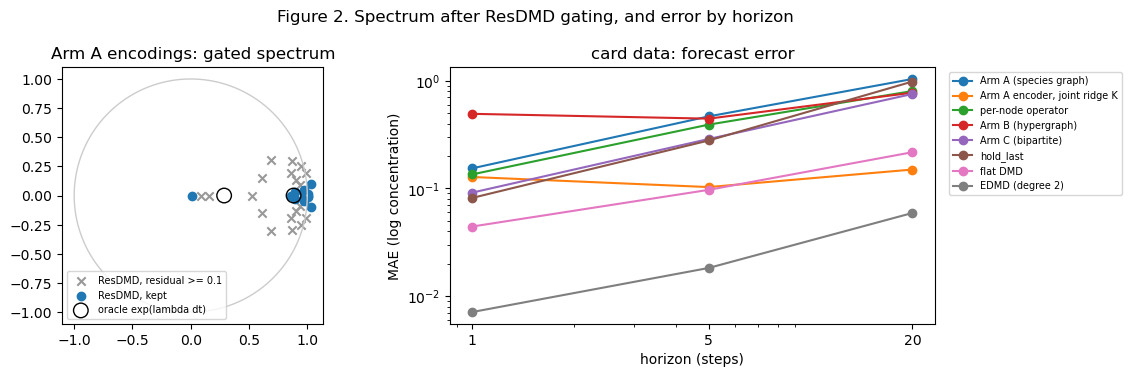

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 3.8))
ax = axes[0]
theta = torch.linspace(0, 2 * math.pi, 200)
ax.plot(torch.cos(theta), torch.sin(theta), color="0.8", linewidth=1)
eigs = report.eigenvalues.to(torch.complex128)
ax.scatter(
    eigs[~gate].real,
    eigs[~gate].imag,
    marker="x",
    color="0.6",
    label="ResDMD, residual >= 0.1",
)
ax.scatter(eigs[gate].real, eigs[gate].imag, marker="o", label="ResDMD, kept")
oracle_points = [math.exp(-dt / t) for t in oracle_tau]
ax.scatter(
    oracle_points,
    [0.0] * len(oracle_points),
    s=110,
    facecolors="none",
    edgecolors="black",
    label="oracle exp(lambda dt)",
)
ax.set_aspect("equal")
ax.set_title("Arm A encodings: gated spectrum")
ax.legend(fontsize=7, loc="lower left")

ax = axes[1]
for name in card_rows:
    ax.plot(HORIZONS, [results[name][h] for h in HORIZONS], marker="o", label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(HORIZONS, [str(h) for h in HORIZONS])
ax.set_xlabel("horizon (steps)")
ax.set_ylabel("MAE (log concentration)")
ax.set_title("card data: forecast error")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle("Figure 2. Spectrum after ResDMD gating, and error by horizon")
fig.tight_layout()
plt.show()

**Reading Table 1.** At this budget the end-to-end Arm A model is
worse than `hold_last` at every horizon, and its operator has an
eigenvalue outside the unit circle. That is a negative result about
the short fit, not about the encodings: the same frozen encoder with a
ridge-refitted joint operator cuts the 20-step error by roughly a
factor of seven. It beats `hold_last` from 5 steps on and flat DMD at
20 steps. At 20 steps the per-node operator and Arms B and C land
between Arm A and the refit; with one seed and 30 epochs their differences are within
training noise and do not rank the encodings. Polynomial EDMD on the
four log concentrations is the strongest forecaster here by a wide
margin, which a four-species system with a smooth vector field allows.

On the fixed-atom-budget family the projection removes the element
drift (down to float32 round-off, from about six percent without it) and
also lowers the forecast error, because the correction moves every
decoded state onto the manifold the data live on. The $k_\mathrm{cat}$
shift is negative transfer: Arm A's error rises several-fold and ends
above `hold_last` on the shifted kinetics.

## Interpretation / discussion

**What a linear latent $K$ can represent.** Michaelis-Menten has a
fast binding mode (oracle timescale $0.4$ s, below one sample of
$\Delta t = 0.5$ s) and a slow catalytic mode ($4$ s). A linear
operator on fixed observables represents relaxation as a sum of
decaying modes, which suits the slow approach to equilibrium. Two
features of these data do not fit that picture. The fast mode has
decayed by $e^{-\Delta t/0.4} \approx 0.3$ within one step, so the data
barely resolve it, and it falls outside the window
$[2\Delta t, T\Delta t]$ used for matching. In log coordinates a
species that decays exponentially falls *linearly* in time until it
reaches the floor, where it stops. A linear $K$ can only mimic that
ramp with an eigenvalue near $1$, and the ramp-then-floor shape is not
an eigenfunction of any linear map.

**Why spurious modes appear and what gating removes.** An operator fitted
to finite data has as many eigenvalues as latent dimensions ($S d = 32$
here), and most are not supported by the data. ResDMD measures how
well each eigenpair satisfies the Koopman relation on held-out pairs
and discards the poorly supported ones. Here gating cut the in-window
modes from about nine to three, and the gated mode nearest the oracle
is within about 15 percent of the $4$ s timescale. The
spurious slow mode that survives gating is real in the data: it is the
log-floor ramp above, not a kinetic timescale. Gating removes modes the
data do not support; it cannot remove modes the observables genuinely
have but the kinetics do not. Comparing against the oracle needs both
steps.

**Constraints belong in the coordinates where they are linear.** Atom
balance is $E c = E c_0$ in raw concentrations, so a min-norm
projection enforces it exactly and cheaply. In log coordinates the same
constraint is nonlinear, and the log model's drift (tens of percent
over 20 steps) is learned error, about six orders of magnitude above
the floor bias. The price of raw features is that a decoder can
produce **negative** concentrations, which the log transform rules out.

**Rate constants are not inputs.** A fixed $K$ encodes the training
kinetics. When $k_\mathrm{cat}$ changes, the encoder still maps states
correctly, but the operator advances them at the old rate, so error
grows with horizon. Transfer across rate constants needs the rate as
an input (a parametric or control-affine operator), and a negative
result here is the expected one.

## Takeaways

- **When to use.** Use the reaction cards to test whether a graph
  Koopman model recovers kinetic structure (timescales, conservation),
  not only forecasts. Always report `hold_last` and EDMD beside it.
- **Diagnose before tuning.** Refit the operator on frozen encodings.
  If the refit is much better, the encoder is fine and the end-to-end
  operator is under-trained or unstable (check $\max|\lambda|$).
- **Gate, then compare.** Compare implied timescales with the oracle
  only after ResDMD gating and Nyquist screening, inside the window the
  sampling resolves. Treat surviving modes far slower than any oracle
  timescale as observable artifacts (the log floor), not kinetics.
- **Balance.** Report element drift next to the floor bias. Enforce
  balance by projection in raw coordinates when it must hold exactly.
- **Gotchas.** The 0.16.0 flat baselines fit one sequence, so pool
  pairs across trajectories yourself. `HypergraphConv` has no root term;
  add singleton hyperedges. Heterogeneous operators need
  `backward=0`. Training budgets this short do not rank encodings.

## Further reading

- Sphinx: [reaction](../docs/source/reaction.rst) (guide),
  [api](../docs/source/api.rst) (`ReactionNetworkBenchmark`,
  `koopman_graph.datasets.reaction`, `koopman_graph.analysis.resdmd`),
  [spectral_diagnostics](../docs/source/spectral_diagnostics.rst)
- Colbrook and Townsend (2024), *Comm. Pure Appl. Math.* 77, 221-283
  ([doi:10.1002/cpa.22125](https://doi.org/10.1002/cpa.22125); ResDMD)
- Williams, Kevrekidis, and Rowley (2015), *J. Nonlinear Sci.* 25,
  1307-1346 ([doi:10.1007/s00332-015-9258-5](https://doi.org/10.1007/s00332-015-9258-5); EDMD)
- Feinberg (2019), *Foundations of Chemical Reaction Network Theory*,
  Springer ([doi:10.1007/978-3-030-03858-8](https://doi.org/10.1007/978-3-030-03858-8))
- Example [55_reaction_network_oracles.ipynb](55_reaction_network_oracles.ipynb)
  (the card oracles with DMD)
- Example [51_spectral_diagnostics.ipynb](51_spectral_diagnostics.ipynb)
- Example [48_identification_invariance.ipynb](48_identification_invariance.ipynb)